In [8]:
%pip install pandas numpy matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Đọc dữ liệu và loại bỏ các dòng không có nhãn Outcome
df_clean = pd.read_csv("../data/diabetes.csv")
df_model = df_clean.dropna(subset=["Outcome"]).copy()

# X: các thuộc tính đầu vào
X = df_model.drop(columns=["Outcome"])

# y: nhãn cần dự đoán
y = df_model["Outcome"].astype(int)

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)
print("Phân bố nhãn:")
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nSố mẫu train:", len(X_train))
print("Số mẫu test:", len(X_test))

Kích thước X: (768, 8)
Kích thước y: (768,)
Phân bố nhãn:
Outcome
0    500
1    268
Name: count, dtype: int64

Số mẫu train: 614
Số mẫu test: 154


TẠO HÀM ĐÁNH GIÁ DÙNG CHUNG

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

results = {}
trained_models = {}

def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        )
    }

    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Không mắc (0)", "Mắc (1)"]
    )

    disp.plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

    return y_pred

XÂY DỰNG DECISION TREE


===== Decision Tree =====
              precision    recall  f1-score   support

           0       0.84      0.84      0.84       100
           1       0.70      0.70      0.70        54

    accuracy                           0.79       154
   macro avg       0.77      0.77      0.77       154
weighted avg       0.79      0.79      0.79       154



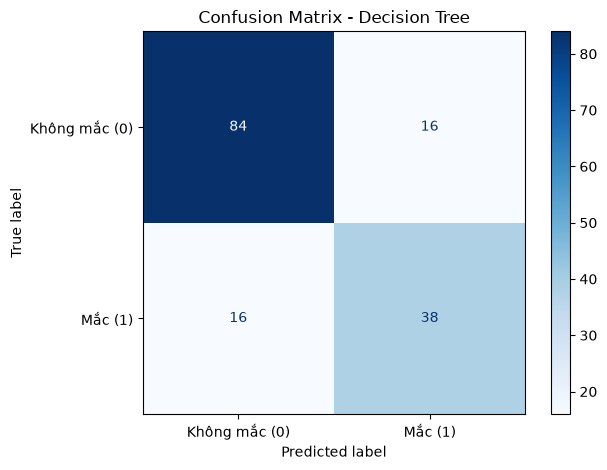

In [17]:
from sklearn.tree import DecisionTreeClassifier

dt_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

trained_models["Decision Tree"] = dt_model

dt_pred = evaluate_model(
    "Decision Tree",
    dt_model,
    X_test,
    y_test
)

VẼ CÂY QUYẾT ĐỊNH

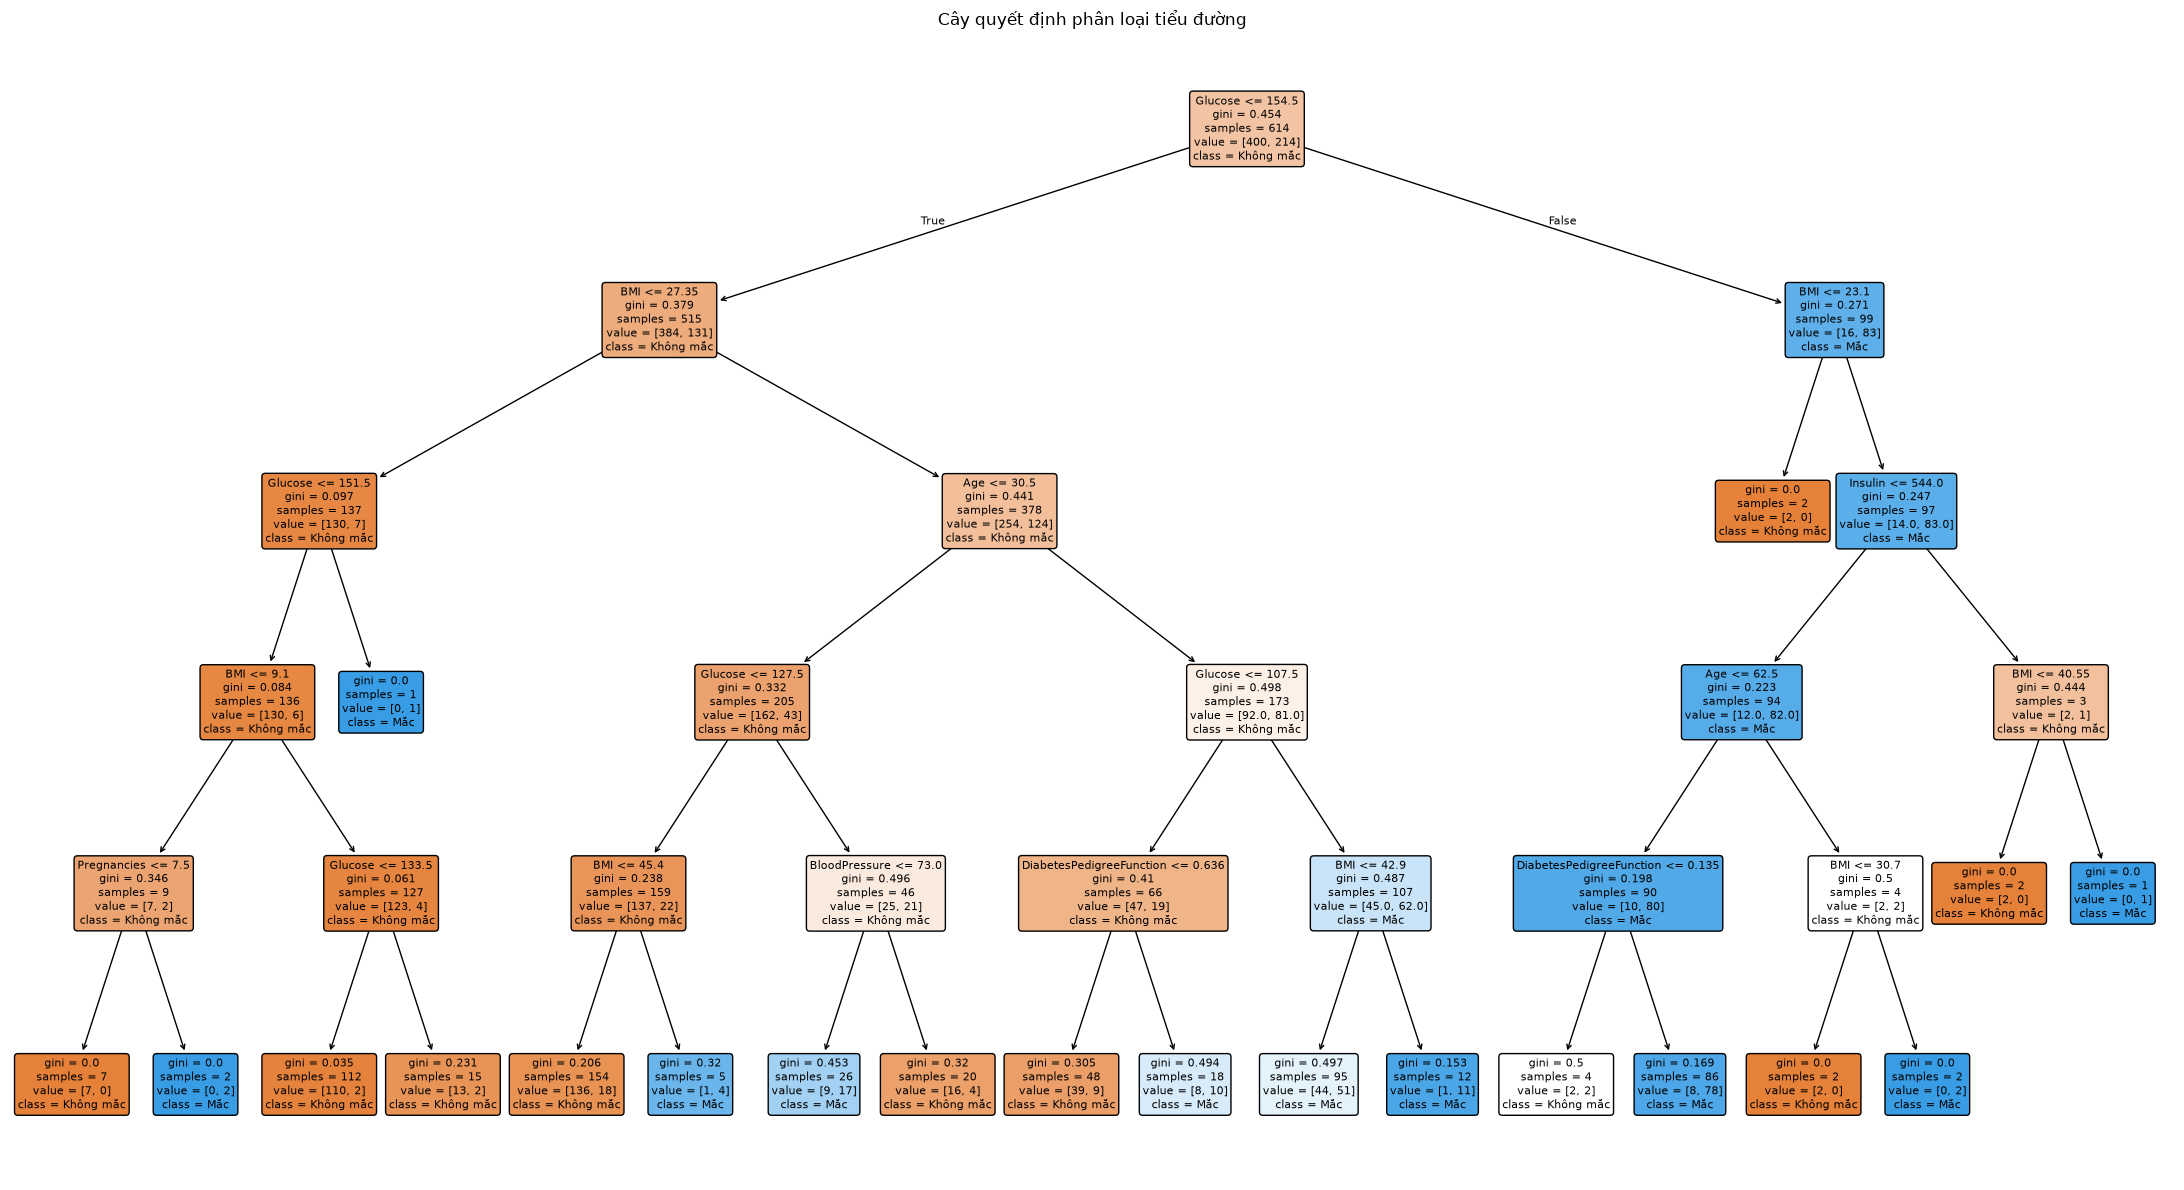

In [18]:
from sklearn.tree import plot_tree

dt_classifier = dt_model.named_steps["classifier"]

plt.figure(figsize=(22, 12))

plot_tree(
    dt_classifier,
    feature_names=X.columns.tolist(),
    class_names=["Không mắc", "Mắc"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Cây quyết định phân loại tiểu đường")
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=200, bbox_inches="tight")
plt.show()

XÂY DỰNG MÔ HÌNH RANDOM FOREST


===== Random Forest =====
              precision    recall  f1-score   support

           0       0.79      0.85      0.82       100
           1       0.68      0.59      0.63        54

    accuracy                           0.76       154
   macro avg       0.74      0.72      0.73       154
weighted avg       0.75      0.76      0.76       154



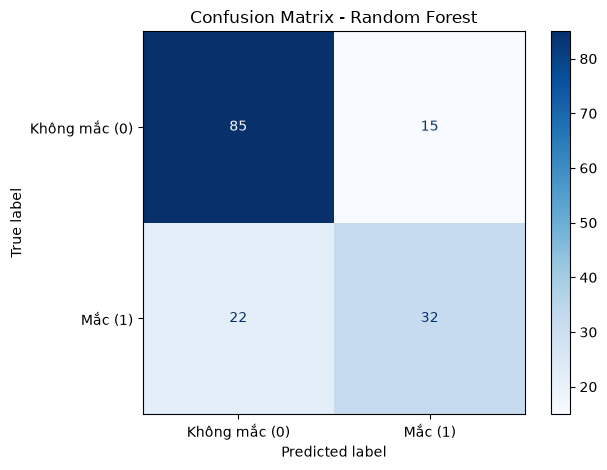

In [19]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

trained_models["Random Forest"] = rf_model

rf_pred = evaluate_model(
    "Random Forest",
    rf_model,
    X_test,
    y_test
)

XEM MỨC ĐỘ QUAN TRỌNG CỦA CÁC THUỘC TÍNH

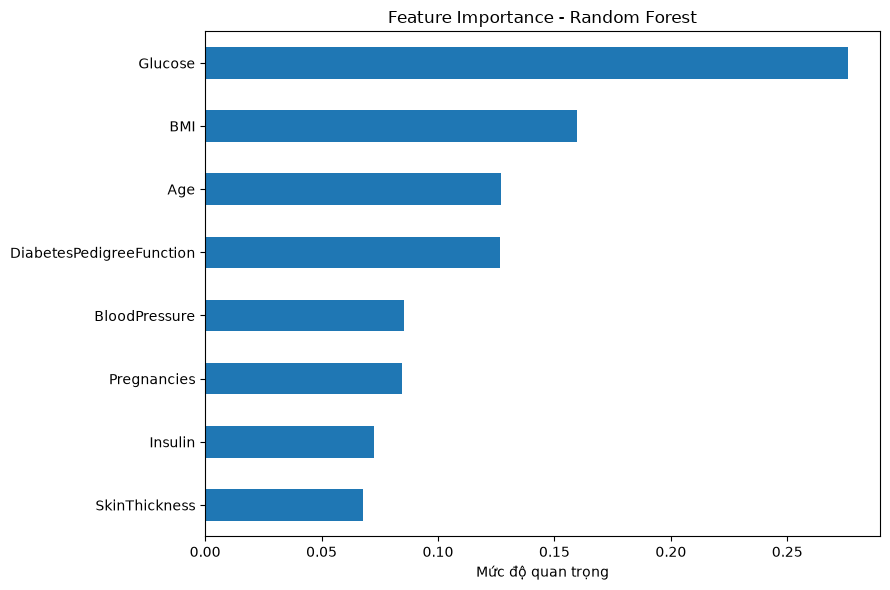

,Importance
Glucose,0.276009
BMI,0.159544
Age,0.127248
DiabetesPedigreeFunction,0.126731
BloodPressure,0.085606
Pregnancies,0.084456
Insulin,0.072409
SkinThickness,0.067997


In [20]:
rf_classifier = rf_model.named_steps["classifier"]

importance = pd.Series(
    rf_classifier.feature_importances_,
    index=X.columns
).sort_values()

plt.figure(figsize=(9, 6))

importance.plot(kind="barh")

plt.title("Feature Importance - Random Forest")
plt.xlabel("Mức độ quan trọng")
plt.tight_layout()
plt.savefig("random_forest_importance.png", dpi=200,
            bbox_inches="tight")
plt.show()

display(importance.sort_values(ascending=False).to_frame(
    "Importance"
))